# v.0 Library Usability 

## Preprocessing: from event logs to session sequences

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [73]:
df = pd.read_csv('../../data/ecommerce_clickstream_transactions.csv')
print(df.shape)
df.head()

(74817, 7)


,UserID,SessionID,Timestamp,EventType,ProductID,Amount,Outcome
0,1,1,2024-07-07 18:00:26.959902,page_view,NaN,NaN,NaN
1,1,1,2024-03-05 22:01:00.072000,page_view,NaN,NaN,NaN
2,1,1,2024-03-23 22:08:10.568453,product_view,prod_8199,NaN,NaN
3,1,1,2024-03-12 00:32:05.495638,add_to_cart,prod_4112,NaN,NaN
4,1,1,2024-02-25 22:43:01.318876,add_to_cart,prod_3354,NaN,NaN


### Clean and sort

In [74]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
df = df.dropna(subset=["UserID", "Timestamp", "EventType"]).drop_duplicates()
df["EventType"] = df["EventType"].str.strip().str.lower()
df = df.sort_values(["UserID", "SessionID", "Timestamp"]).reset_index(drop=True)
df["EventType"].value_counts()

EventType
page_view       10819
add_to_cart     10735
product_view    10696
logout          10685
purchase        10682
click           10632
login           10568
Name: count, dtype: int64

In [75]:
df.head()

,UserID,SessionID,Timestamp,EventType,ProductID,Amount,Outcome
0,1,1,2024-01-01 23:09:51.956825,page_view,NaN,NaN,NaN
1,1,1,2024-02-01 05:13:26.944169,add_to_cart,prod_4965,NaN,NaN
2,1,1,2024-02-14 15:41:53.071258,login,NaN,NaN,NaN
3,1,1,2024-02-25 22:43:01.318876,add_to_cart,prod_3354,NaN,NaN
4,1,1,2024-03-05 22:01:00.072000,page_view,NaN,NaN,NaN


In [76]:
g = df.groupby(["UserID", "SessionID"])["Timestamp"]
span_h = (g.max() - g.min()).dt.total_seconds() / 3600
gaps_min = g.diff().dt.total_seconds() / 60
print(f"Median session span: {span_h.median():.2f} hours | Max session span: {span_h.max():.2f} hours")
print(f"Gaps longer than 30 minutes: {(gaps_min > 30).mean() * 100:.2f}%")

Median session span: 3847.17 hours | Max session span: 4920.10 hours
Gaps longer than 30 minutes: 86.55%


#### Define sessions

Choose one. `SESSION_MODE = 'session_id'` uses the given IDs; `'inactivity'` starts a new session after 30 min of silence per user.

In [77]:
SESSION_MODE = "session_id"   # or "inactivity"
GAP_MIN = 30

if SESSION_MODE == "session_id":
    df["session_key"] = df.groupby(["UserID", "SessionID"]).ngroup()
else:
    df = df.sort_values(["UserID", "Timestamp"])
    new = df.groupby("UserID")["Timestamp"].diff().gt(pd.Timedelta(minutes=GAP_MIN))
    new |= df["UserID"].ne(df["UserID"].shift())
    df["session_key"] = new.cumsum()

#### Build sequences and filter by length

In [78]:
df = df.sort_values(["session_key", "Timestamp"])
sessions = (df.groupby("session_key")
              .agg(user=("UserID", "first"),
                   events=("EventType", list),
                   outcome=("Outcome", lambda s: s.dropna().iloc[-1] if s.notna().any() else None),
                   total_amount=("Amount", "sum")))
sessions["n_events"] = sessions["events"].str.len()

hi = np.percentile(sessions["n_events"], 99)
sessions = sessions[(sessions["n_events"] >= 2) & (sessions["n_events"] <= hi)]

sequences = sessions["events"].tolist()   # list[list[str]] -> input for Levenshtein
print(len(sequences), "sessions")
sessions.head()

10000 sessions


,user,events,outcome,total_amount,n_events
session_key,,,,,
0,1,"[page_view, add_to_cart, login, add_to_cart, p...",None,0.000000,9
1,1,"[page_view, page_view, logout, product_view, c...",None,0.000000,6
2,1,"[page_view, login, add_to_cart, click, add_to_...",purchase,72.913619,9
3,1,"[add_to_cart, add_to_cart, login, page_view, a...",purchase,7.677938,10
4,1,"[logout, purchase, purchase, product_view, log...",purchase,998.570616,9


## Testing `BaselineAligner` (Stage 1: Levenshtein distance matrix)

### 0. Import the library
Install once from a terminal (folder containing `pyproject.toml`): `pip install -e .`

In [79]:
import sys
from pathlib import Path

# Add v0.2/ root to sys.path so `journey_analyzer` imports cleanly from notebooks/
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Top-level API import (tests journey_analyzer/__init__.py)
from journey_analyzer import BaselineAligner

# Sub-package pure function imports (tests journey_analyzer/alignment/__init__.py)
from journey_analyzer.alignment import (
    assign_stages,
    levenshtein_distance,
    normalized_levenshtein_distance,
    weighted_levenshtein_distance,
)

print("Successfully imported BaselineAligner and distance functions!")

Successfully imported BaselineAligner and distance functions!


In [80]:
import time
from journey_analyzer import BaselineAligner
from journey_analyzer.alignment import levenshtein_distance, normalized_levenshtein_distance

In [81]:
import sys
from pathlib import Path

# Add v0.2/ root to sys.path so `journey_analyzer` imports cleanly from notebooks/
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Top-level API import (tests journey_analyzer/__init__.py)
from journey_analyzer import BaselineAligner

# Sub-package pure function imports (tests journey_analyzer/alignment/__init__.py)
from journey_analyzer.alignment import (
    assign_stages,
    levenshtein_distance,
    normalized_levenshtein_distance,
    weighted_levenshtein_distance,
)

print("Successfully imported BaselineAligner and distance functions!")

Successfully imported BaselineAligner and distance functions!


In [82]:
import time
from journey_analyzer import BaselineAligner
from journey_analyzer.alignment import levenshtein_distance, normalized_levenshtein_distance

### 1. Sanity check on hand-made journeys
Before trusting 10,000 sessions we check the metric on cases where we know the answer.

In [83]:
a = ["login", "product_view", "add_to_cart", "purchase"]
b = ["login", "product_view", "purchase"]                  # a without 'add_to_cart'
c = ["logout", "click", "click", "page_view"]              # nothing in common with a

print("a vs a :", levenshtein_distance(a, a))                    # 0 -> identical
print("a vs b :", levenshtein_distance(a, b))                    # 1 -> one deletion
print("a vs c :", levenshtein_distance(a, c))                    # 4 -> four substitutions
print("a vs c normalized:", normalized_levenshtein_distance(a, c))  # 1.0 -> completely different

a vs a : 0.0
a vs b : 1.0
a vs c : 4.0
a vs c normalized: 1.0


### 2. Distance matrix on a random sample of 500 sessions (Experiment 1 scale)
We sample randomly (not `sequences[:500]`), because sessions are stored user by user and the first rows would all belong to the same few users.

In [84]:
rng = np.random.default_rng(42)
idx = rng.choice(len(sequences), size=500, replace=False)
sample = [sequences[i] for i in idx]
print("Sample randomly taken e.g: ", sample[:3])

aligner = BaselineAligner(metric="levenshtein")
t0 = time.perf_counter()
D = aligner.fit_distance_matrix(sample)
print(("\nResultant distance matrix:"))
print(D)
print(f"\nMatrix {D.shape} computed in {time.perf_counter() - t0:.1f} s")

Sample randomly taken e.g:  [['logout', 'login', 'click', 'add_to_cart', 'add_to_cart'], ['logout', 'click', 'login', 'purchase', 'add_to_cart', 'login'], ['click', 'page_view', 'page_view', 'login', 'click', 'page_view', 'page_view', 'logout']]

Resultant distance matrix:
[[ 0.  3.  6. ...  8.  9.  7.]
 [ 3.  0.  7. ...  8.  8.  8.]
 [ 6.  7.  0. ...  8.  8.  8.]
 ...
 [ 8.  8.  8. ...  0.  7.  9.]
 [ 9.  8.  8. ...  7.  0. 10.]
 [ 7.  8.  8. ...  9. 10.  0.]]

Matrix (500, 500) computed in 2.0 s


### 3. Are the matrix properties right?

In [85]:
print("symmetric       :", np.allclose(D, D.T))
print("zero diagonal   :", bool(np.all(np.diag(D) == 0))) # each journey is identical to itself 
print("non-negative    :", bool(D.min() >= 0))

upper = D[np.triu_indices_from(D, k=1)]          # each pair counted once
print(f"pairs: {len(upper):,} | min {upper.min():.0f} | mean {upper.mean():.2f} | max {upper.max():.0f}")
print("read-only matrix:", not D.flags.writeable)

# Very important to check... if not we have a bug in the code or enormous error in the data 

symmetric       : True
zero diagonal   : True
non-negative    : True
pairs: 124,750 | min 0 | mean 6.55 | max 10
read-only matrix: True


### 4. Distribution of distances
If the data had real behavioural groups we would expect several bumps (small distances inside a group, large between groups).

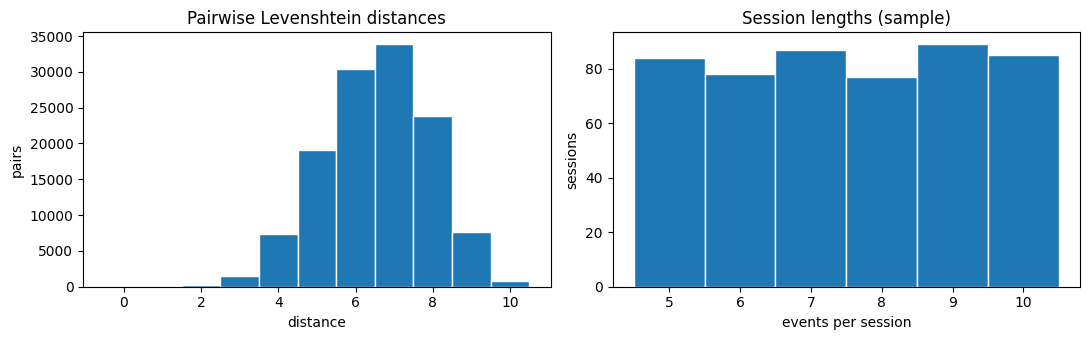

In [86]:
lens = np.array([len(s) for s in sample])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(upper, bins=np.arange(upper.min(), upper.max() + 2) - 0.5, edgecolor="white")
ax[0].set(title="Pairwise Levenshtein distances", xlabel="distance", ylabel="pairs")
ax[1].hist(lens, bins=np.arange(lens.min(), lens.max() + 2) - 0.5, edgecolor="white")
ax[1].set(title="Session lengths (sample)", xlabel="events per session", ylabel="sessions")
plt.tight_layout(); plt.show()

### 5. Look at actual journeys: closest vs. farthest pair

In [87]:
M = D.copy(); np.fill_diagonal(M, np.inf)
i, j = np.unravel_index(M.argmin(), M.shape)
print("MOST SIMILAR pair, distance", D[i, j]); print("  ", sample[i]); print("  ", sample[j])

M = D.copy(); np.fill_diagonal(M, -np.inf)
i, j = np.unravel_index(M.argmax(), M.shape)
print("\nMOST DIFFERENT pair, distance", D[i, j]); print("  ", sample[i]); print("  ", sample[j])

MOST SIMILAR pair, distance 0.0
   ['add_to_cart', 'login', 'purchase', 'purchase', 'page_view']
   ['add_to_cart', 'login', 'purchase', 'purchase', 'page_view']

MOST DIFFERENT pair, distance 10.0
   ['logout', 'click', 'login', 'purchase', 'add_to_cart', 'login']
   ['product_view', 'page_view', 'purchase', 'page_view', 'product_view', 'product_view', 'product_view', 'product_view', 'product_view', 'add_to_cart']


### 6. Weighted metric (stage-aware)
Stages follow Kinjo (2025): pre-purchase, purchase, post-purchase. Here the purchase stage counts 3x.

In [88]:
STAGES = {"login": "pre", "page_view": "pre", "product_view": "pre", "click": "pre",
          "add_to_cart": "pre", "purchase": "purchase", "logout": "post"}

aligner_w = BaselineAligner("weighted", stage_weights={"purchase": 4.0}, event_to_stage=STAGES)
D_w = aligner_w.fit_distance_matrix(sample) 
upper_w = D_w[np.triu_indices_from(D_w, k=1)]

# We are  comparing now the D matrix with and without weights 
print("Spearman correlation, plain vs weighted:", 
      round(pd.Series(upper).corr(pd.Series(upper_w), method="spearman"), 3))
print(f"mean plain {upper.mean():.2f} | mean weighted {upper_w.mean():.2f}")

Spearman correlation, plain vs weighted: 0.439
mean plain 6.55 | mean weighted 9.90


We see that it orders the pairs following the same distribution.

But the mean of the distances is now higher, separating more the journeys if there was a purchase or not.

### 7. Runtime growth

seconds: [0.02, 0.08, 0.3, 1.34] | estimated exponent: 2.06
Extrapolation to all 10,000 sessions: ~13.9 minutes


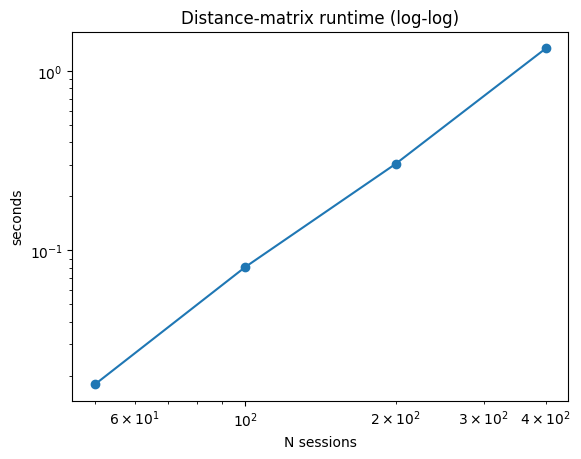

In [89]:
sizes = [50, 100, 200, 400]
times = []
for n in sizes:
    t0 = time.perf_counter()
    BaselineAligner().fit_distance_matrix(sample[:n])
    times.append(time.perf_counter() - t0)

slope = np.polyfit(np.log(sizes), np.log(times), 1)[0]     # slope of log-log line = exponent
print("seconds:", [round(t, 2) for t in times], "| estimated exponent:", round(slope, 2))

n_all = len(sequences)
est_h = times[-1] * (n_all / sizes[-1]) ** 2 / 3600
print(f"Extrapolation to all {n_all:,} sessions: ~{est_h*60:.1f} minutes")

plt.loglog(sizes, times, "o-"); plt.xlabel("N sessions"); plt.ylabel("seconds")
plt.title("Distance-matrix runtime (log-log)"); plt.show()

So the runtime is quadratic as in theory.

### 8. Memory guard
The aligner refuses to allocate a matrix above `max_matrix_gb`, before it starts computing.

In [90]:
# In the library we set it to a default limit to 0.4GB (needed to fit our 10000 sequences)
# For testing reasons we are going to try to set the max now to 0.1GB and try to fit our entire sequences..
try:
    BaselineAligner(max_matrix_gb=0.1).fit_distance_matrix(sequences)   # 10,000 x 10,000 float32 = 0.4 GB
except MemoryError as e:
    print("MemoryError:", e)

MemoryError: A 10000 x 10000 float32 distance matrix needs ~0.4 GB (limit 0.1 GB). Use a subsample or switch to the O(N) methods (k-grams / LDA / SBERT).


## Prototype extraction with k-medoids (PAM)
A **medoid** is the real session with the smallest total distance to the other sessions of its cluster, so each prototype is an actual user journey. We first run a **control experiment** on data where we know the groups exist, to prove the algorithm works. Then we run it on the real sample.

### 9. Control experiment: planted journey types
Three journey templates (buyer, browser, bouncer) with random edits (deletions, substitutions, insertions). PAM should recover them.

In [91]:
templates = {
    "buyer":   ["login", "product_view", "add_to_cart", "purchase", "logout"],
    "browser": ["login", "page_view", "click", "click", "page_view", "logout"],
    "bouncer": ["login", "product_view", "product_view", "product_view", "logout"],
}
all_events = sorted({e for t in templates.values() for e in t})
rng_c = np.random.default_rng(0)

def noisy(template, p=0.15):
    out = []
    for e in template:
        r = rng_c.random()
        if r < p / 3:   continue                                  # delete the event
        if r < 2*p / 3: out.append(str(rng_c.choice(all_events))); continue   # substitute it
        if r < p:       out.append(str(rng_c.choice(all_events)))              # insert one before it
        out.append(e)
    return out

planted, truth = [], []
for name, t in templates.items():
    for _ in range(150):
        planted.append(noisy(t)); truth.append(name)

al_planted = BaselineAligner()
al_planted.fit_distance_matrix(planted)
res_p = al_planted.extract_prototypes(k=3)

print(pd.crosstab(pd.Series(truth, name="true type"), pd.Series(res_p["labels"], name="found cluster")))
for c, (size, proto) in enumerate(zip(res_p["sizes"], res_p["prototypes"])):
    print(f"cluster {c} ({size} sessions) prototype: {proto}")
print("silhouette:", round(al_planted.silhouette_score(), 3), "| swaps:", res_p["n_iter"], "| converged:", res_p["converged"])

found cluster    0    1    2
true type                   
bouncer          8    0  142
browser          1  149    0
buyer          150    0    0
cluster 0 (159 sessions) prototype: ['login', 'product_view', 'add_to_cart', 'purchase', 'logout']
cluster 1 (149 sessions) prototype: ['login', 'page_view', 'click', 'click', 'page_view', 'logout']
cluster 2 (142 sessions) prototype: ['login', 'product_view', 'product_view', 'product_view', 'logout']
silhouette: 0.559 | swaps: 0 | converged: True


### 10. k-medoids on the real sample (k = 4)

inertia 2365 | swaps 0 | converged True | silhouette 0.025
cluster 0: 208 sessions | prototype (5 events): ['login', 'add_to_cart', 'purchase', 'click', 'logout']
cluster 1: 134 sessions | prototype (5 events): ['add_to_cart', 'product_view', 'logout', 'page_view', 'product_view']
cluster 2:  90 sessions | prototype (6 events): ['click', 'login', 'page_view', 'product_view', 'purchase', 'page_view']
cluster 3:  68 sessions | prototype (5 events): ['logout', 'purchase', 'click', 'product_view', 'login']


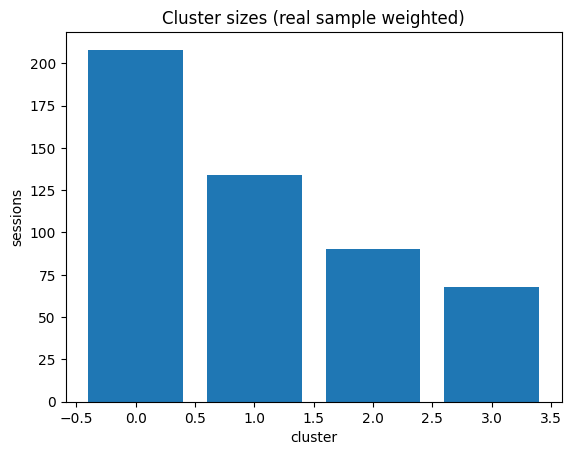

In [119]:
res = aligner.extract_prototypes(k=4)

print(f"inertia {res['inertia']:.0f} | swaps {res['n_iter']} | converged {res['converged']} "
      f"| silhouette {aligner.silhouette_score():.3f}")
for c, (size, proto) in enumerate(zip(res["sizes"], res["prototypes"])):
    print(f"cluster {c}: {size:>3} sessions | prototype ({len(proto)} events): {proto}")

plt.bar(range(4), res["sizes"]); plt.xlabel("cluster"); plt.ylabel("sessions")
plt.title("Cluster sizes (real sample weighted)"); plt.show()

inertia 2344 | swaps 1 | converged True | silhouette 0.396
cluster 0: 201 sessions | prototype (6 events): ['click', 'logout', 'add_to_cart', 'page_view', 'purchase', 'login']
cluster 1: 158 sessions | prototype (6 events): ['page_view', 'login', 'click', 'product_view', 'page_view', 'logout']
cluster 2:  96 sessions | prototype (6 events): ['logout', 'page_view', 'product_view', 'purchase', 'purchase', 'add_to_cart']
cluster 3:  45 sessions | prototype (7 events): ['logout', 'add_to_cart', 'purchase', 'page_view', 'purchase', 'purchase', 'click']


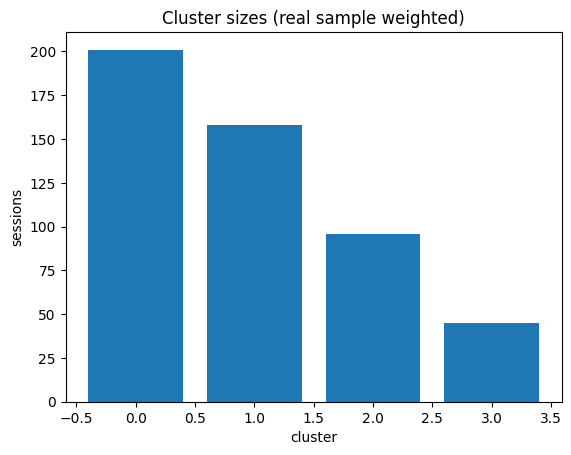

In [120]:
res = aligner_w.extract_prototypes(k=4)

print(f"inertia {res['inertia']:.0f} | swaps {res['n_iter']} | converged {res['converged']} "
      f"| silhouette {aligner_w.silhouette_score():.3f}")
for c, (size, proto) in enumerate(zip(res["sizes"], res["prototypes"])):
    print(f"cluster {c}: {size:>3} sessions | prototype ({len(proto)} events): {proto}")

plt.bar(range(4), res["sizes"]); plt.xlabel("cluster"); plt.ylabel("sessions")
plt.title("Cluster sizes (real sample weighted)"); plt.show()

### 11. How many clusters? Inertia and silhouette for k = 2..10
Inertia always decreases with k, so look for an elbow. Silhouette should peak at the natural number of groups (3 in the control experiment).

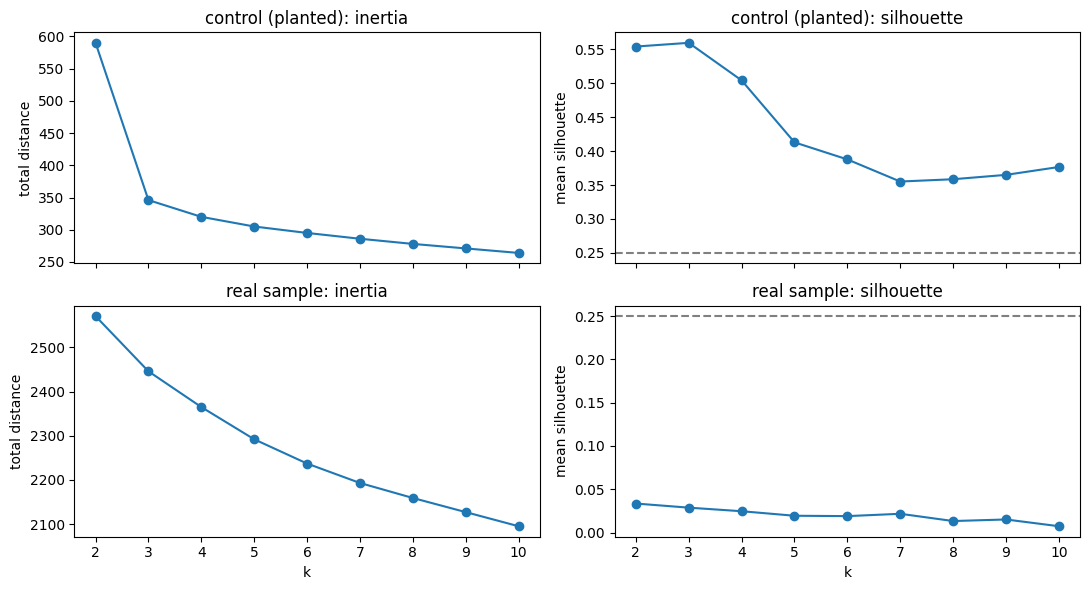

In [121]:
ks = range(2, 11)
def sweep(al):
    inertia, sil = [], []
    for k in ks:
        r = al.extract_prototypes(k)
        inertia.append(r["inertia"]); sil.append(al.silhouette_score())
    return inertia, sil

fig, ax = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for row, (name, al) in enumerate([("control (planted)", al_planted), ("real sample", aligner)]):
    inertia, sil = sweep(al)
    ax[row, 0].plot(list(ks), inertia, "o-"); ax[row, 0].set(title=f"{name}: inertia", ylabel="total distance")
    ax[row, 1].plot(list(ks), sil, "o-");     ax[row, 1].set(title=f"{name}: silhouette", ylabel="mean silhouette")
    ax[row, 1].axhline(0.25, ls="--", c="grey")      # below this: no substantial structure
ax[1, 0].set_xlabel("k"); ax[1, 1].set_xlabel("k")
plt.tight_layout(); plt.show()

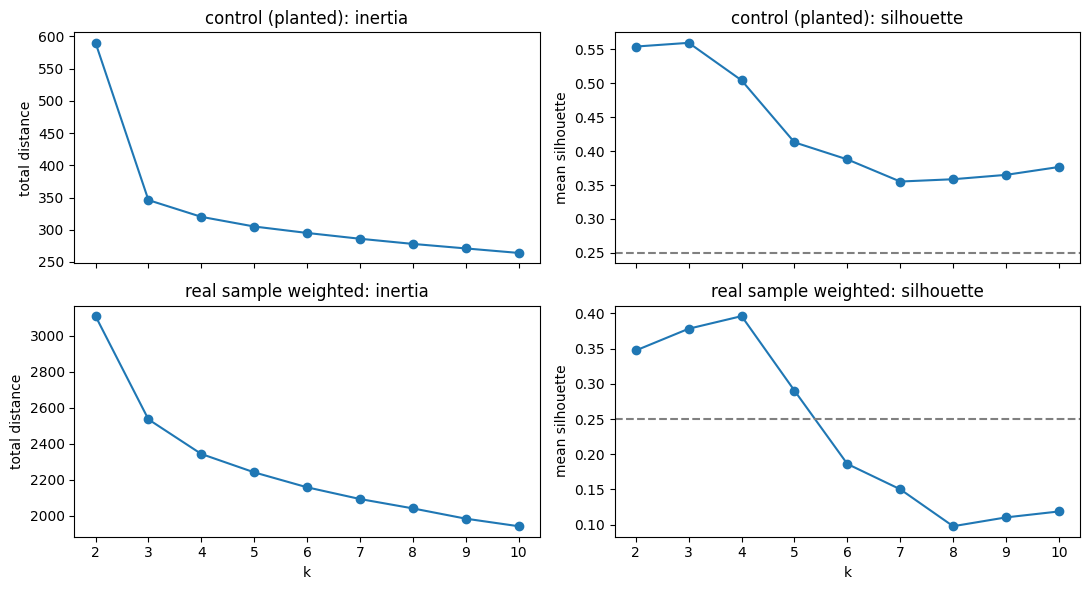

In [122]:
ks = range(2, 11)
def sweep(al):
    inertia, sil = [], []
    for k in ks:
        r = al.extract_prototypes(k)
        inertia.append(r["inertia"]); sil.append(al.silhouette_score())
    return inertia, sil

fig, ax = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for row, (name, al) in enumerate([("control (planted)", al_planted), ("real sample weighted", aligner_w)]):
    inertia, sil = sweep(al)
    ax[row, 0].plot(list(ks), inertia, "o-"); ax[row, 0].set(title=f"{name}: inertia", ylabel="total distance")
    ax[row, 1].plot(list(ks), sil, "o-");     ax[row, 1].set(title=f"{name}: silhouette", ylabel="mean silhouette")
    ax[row, 1].axhline(0.25, ls="--", c="grey")      # below this: no substantial structure
ax[1, 0].set_xlabel("k"); ax[1, 1].set_xlabel("k")
plt.tight_layout(); plt.show()

The algorithm works perfectly, but strict sequential alignment is not the right fit for your real data (WITHOUTH WEIGHTED DISTANCE)

There is no existing underlaying structure to be found. 

Because the real user journeys are clearly too noisy or non-linear for Levenshtein distance, optimizing k further will not yield better results. Transitioning away from strict edit distances toward other methods could be more useful.

### 12. Is PAM better than chance? BUILD vs. random restarts vs. random medoids

In [123]:
D_ = aligner.distance_matrix
rng_r = np.random.default_rng(1)
rand_costs = [D_[rng_r.choice(len(D_), 5, replace=False)].min(axis=0).sum() for _ in range(300)]

aligner.extract_prototypes(5)
inertia_build = aligner.inertia_
inertia_rand = aligner.extract_prototypes(5, init="random", n_init=10, random_state=0)["inertia"]
aligner.extract_prototypes(5)                       # leave the BUILD result as the current one

print(f"PAM (BUILD)              : {inertia_build:.0f}")
print(f"PAM (random, 10 restarts): {inertia_rand:.0f}")
print(f"300 random medoid sets   : best {min(rand_costs):.0f} | mean {np.mean(rand_costs):.0f} | worst {max(rand_costs):.0f}")

PAM (BUILD)              : 2292
PAM (random, 10 restarts): 2291
300 random medoid sets   : best 2376 | mean 2560 | worst 2996


### 13. Do the weighted-metric prototypes differ?
Same sessions, but the purchase stage counts 3x (`aligner_w` from section 6).

In [130]:
res_w = aligner_w.extract_prototypes(k=4)
print(f"silhouette plain {aligner.silhouette_score():.3f} | weighted {aligner_w.silhouette_score():.3f}")
for c, (size, proto) in enumerate(zip(res_w["sizes"], res_w["prototypes"])):
    print(f"cluster {c}: {size:>3} sessions | prototype: {proto}")

# do the two clusterings agree on which sessions belong together?
agree = pd.crosstab(pd.Series(aligner.labels_, name="plain"), pd.Series(aligner_w.labels_, name="weighted"))
agree

silhouette plain 0.019 | weighted 0.396
cluster 0: 201 sessions | prototype: ['click', 'logout', 'add_to_cart', 'page_view', 'purchase', 'login']
cluster 1: 158 sessions | prototype: ['page_view', 'login', 'click', 'product_view', 'page_view', 'logout']
cluster 2:  96 sessions | prototype: ['logout', 'page_view', 'product_view', 'purchase', 'purchase', 'add_to_cart']
cluster 3:  45 sessions | prototype: ['logout', 'add_to_cart', 'purchase', 'page_view', 'purchase', 'purchase', 'click']


weighted,0,1,2,3
plain,,,,
0,73,39,44,21
1,53,41,13,9
2,33,30,20,7
3,24,15,13,7
4,18,33,6,1


## Visualizing the clusters
`plot_clusters` projects the sessions to 2D with MDS (so that close sessions in the distance matrix are close on the plot) and draws:
- **Left:** sessions coloured by cluster, medoids as stars, faint lines from every session to its medoid.
- **Right:** the same points coloured by each session's own **silhouette** (green = well inside its cluster, red = misplaced).

The title reports how faithful the 2D picture is (*stress*: lower is better). Many sessions are identical journeys and would overlap exactly, so points are jittered slightly for display.

### 14. Control experiment: three planted journey types

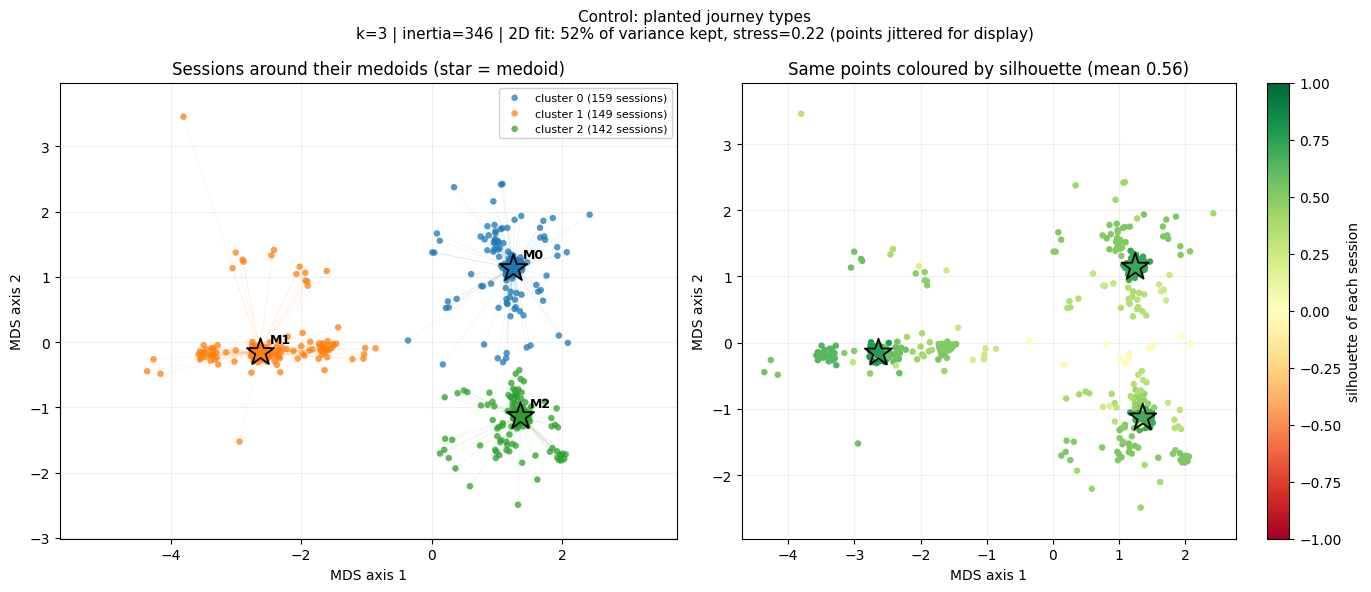

In [132]:
al_planted.extract_prototypes(k=3)            # earlier cells left this object with k=10
fig, X_planted = al_planted.plot_clusters(title="Control: planted journey types")
plt.show()

### 15. Real sample (k = 4)

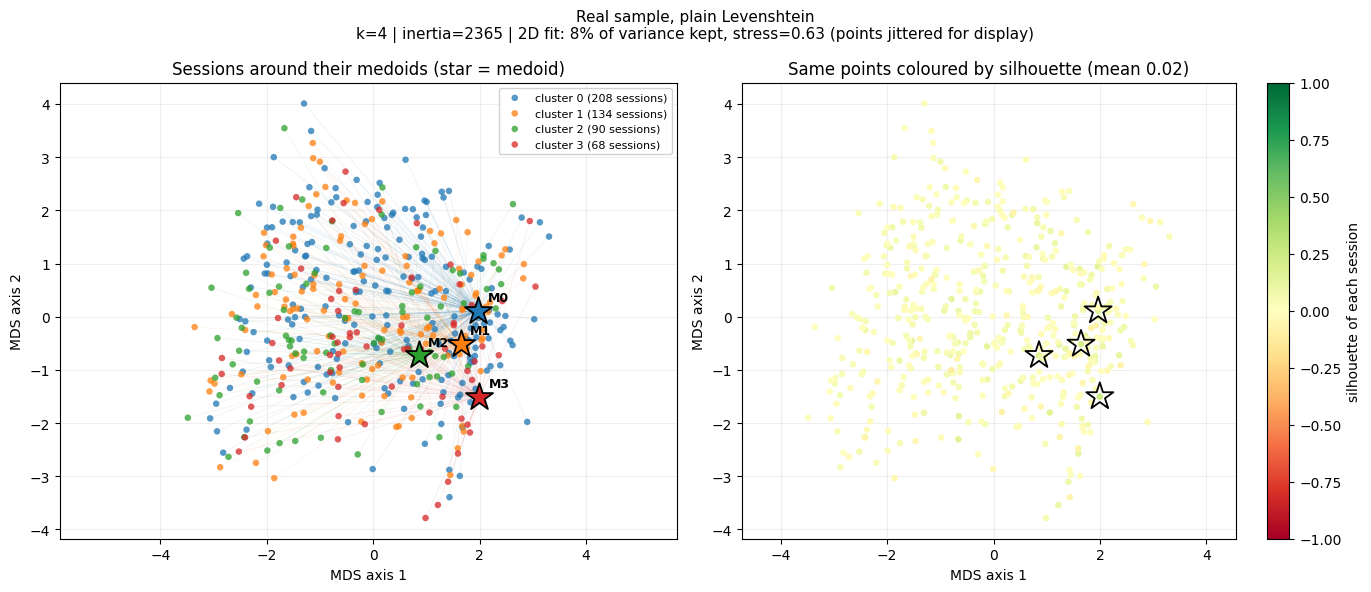

In [134]:
aligner.extract_prototypes(k=4)               # earlier cells left this object with another k
fig, X_sample = aligner.plot_clusters(title="Real sample, plain Levenshtein")
plt.show()

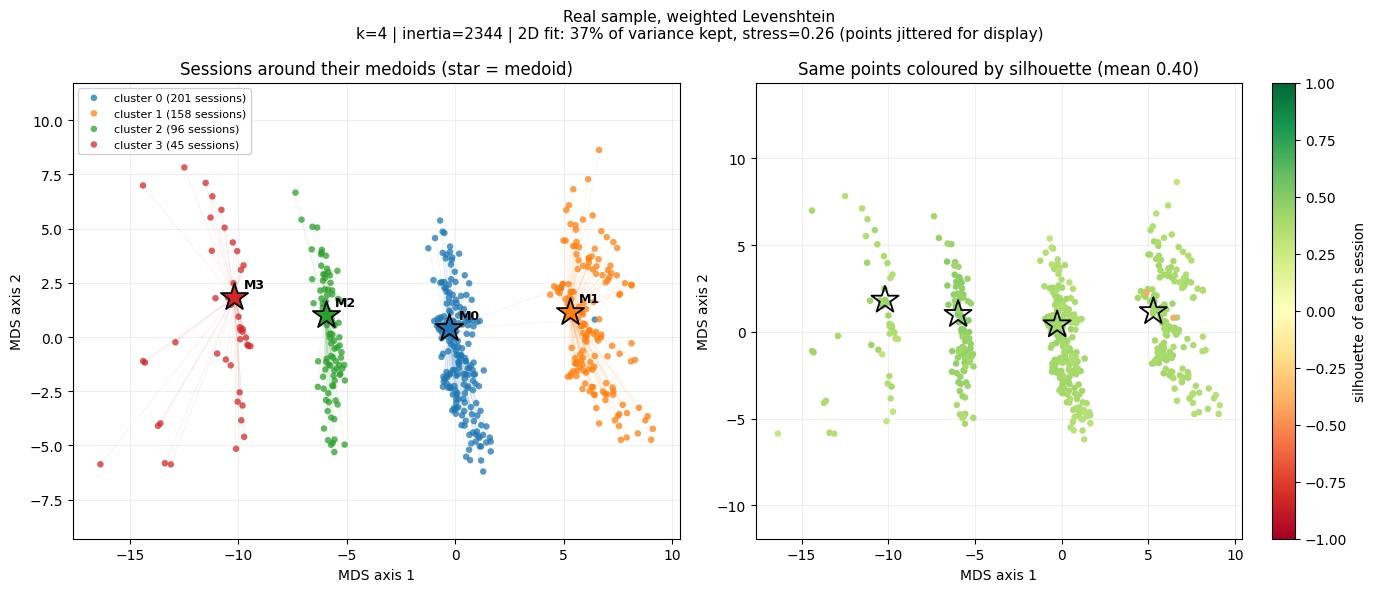

In [135]:
fig, X_sample = aligner_w.plot_clusters(title="Real sample, weighted Levenshtein")
plt.show()

### 16. How many sessions are probably misplaced?
Sessions with a negative silhouette are closer, on average, to another cluster than to their own.

In [136]:
from journey_analyzer.alignment import silhouette_samples_from_distances

for name, al in [("control", al_planted), ("real sample", aligner_w)]:
    s = silhouette_samples_from_distances(al.distance_matrix, al.labels_)
    print(f"{name:12s} mean {s.mean():+.2f} | negative: {(s < 0).mean():5.1%} | above 0.4: {(s > 0.4).mean():5.1%}")

control      mean +0.56 | negative:  2.2% | above 0.4: 80.4%
real sample  mean +0.40 | negative:  0.4% | above 0.4: 51.8%
